# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

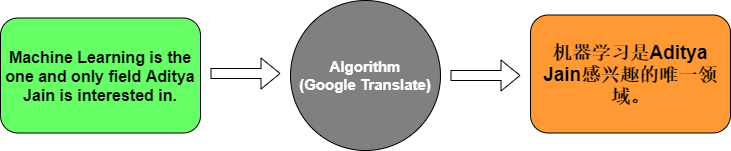

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow info messages

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]])

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.0000e+00 - loss: 2.4859
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.0000e+00 - loss: 2.4859 - val_accuracy: 0.0000e+00 - val_loss: 2.4870
Epoch 2/50

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5714 - loss: 2.4779
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5714 - loss: 2.4779 - val_accuracy: 0.0000e+00 - val_loss: 2.4887
Epoch 3/50

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5714 - loss: 2.4700
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5714 - loss: 2.4700 - val_accuracy: 0.0000e+00 - val_loss: 2.4906
Epoch 4/50

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5714 - loss: 2.4617
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.5714 - loss: 2.4617 - val_accuracy: 0.0000e+00 - val_loss: 2.4925
Epoch 5/50

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5714 - loss: 2.4526
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.5714 - loss: 2.4526 - val_accuracy: 0.0000e+00 - val

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


### ✅ Solution – Task 1

**1. What does the Embedding layer do to a word index?**
It works like a lookup table: each word index (e.g. `5`) is replaced by a dense vector of real numbers (here 64 numbers). These vectors are learned during training, so words that are used in similar ways end up with similar vectors – much richer than a single integer or a huge one-hot vector.

**3. What is the role of the Encoder LSTM?**
It reads the English sentence one word-vector at a time and keeps updating its internal (hidden/cell) state. After the last word, its final state is a fixed-size vector (64 numbers) that summarises the meaning of the whole input sentence – the "context vector". `RepeatVector` then copies this summary once for every output time step.

**5. What does the Decoder LSTM do?**
It takes the encoder's summary (repeated at every step) and, with `return_sequences=True`, produces one output vector per position of the French sentence. Each of these vectors holds the information needed to decide which French word should appear at that position, i.e. it unfolds the summary back into a sequence.

**8. Why do we use `softmax` in the final layer?**
At every time step the `Dense` layer gives one score per word in the French vocabulary. `softmax` turns these scores into a probability distribution (all values between 0 and 1, summing to 1). This lets us pick the most likely word with `argmax` and train the network with `sparse_categorical_crossentropy`, which compares this probability distribution with the correct word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

### ✅ Solution – Task 2 – English → French translation

Plan:
1. Load the Kaggle English–French sentence pairs.
2. Pre-process: lower-case, keep short sentences (the simple encoder–decoder from the lab cannot handle long ones well) and take a random subset so training is feasible on a CPU.
3. Tokenize & pad both languages (English pre-padded, French **post**-padded so the words start at the first time step).
4. Train the same *Embedding → LSTM encoder → RepeatVector → LSTM decoder → softmax* architecture from the lab, but larger.
5. Evaluate on a held-out test set: token accuracy (ignoring padding), BLEU score and example translations.

In [8]:
import os, re
import numpy as np
import pandas as pd
import tensorflow as tf
import kagglehub
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

tf.random.set_seed(42)
np.random.seed(42)

mt_path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
print(os.listdir(mt_path))
pairs = pd.read_csv(os.path.join(mt_path, "eng_-french.csv"))
pairs.columns = ["english", "french"]
print("Sentence pairs:", len(pairs))
pairs.sample(5, random_state=1)

['eng_-french.csv']
Sentence pairs: 175621


,english,french
37931,Tom checked the date.,Tom a vérifié la date.
142019,That TV station broadcasts only movies.,Cette chaîne de télévision diffuse uniquement ...
63699,Tell me what I did wrong.,Dites-moi ce que j'ai fait de travers !
37669,They want more space.,Ils veulent plus d'espace.
165392,"If I had more money, I could move to a bigger ...","Si j'avais davantage d'argent, je pourrais dém..."


In [9]:
# 2. Pre-processing
def clean(s):
    s = s.lower().strip()
    s = re.sub(r"[\u2019\u2018]", "'", s)      # curly apostrophes -> straight
    s = re.sub(r"\s+", " ", s)
    return s

pairs = pairs.dropna().drop_duplicates()
pairs["english"] = pairs["english"].apply(clean)
pairs["french"] = pairs["french"].apply(clean)

MAX_WORDS = 6        # keep short sentences only
N_SAMPLES = 25000    # subset size so training runs in a few minutes on CPU

short = pairs[(pairs.english.str.split().str.len() <= MAX_WORDS) &
              (pairs.french.str.split().str.len() <= MAX_WORDS + 2)]
data = short.sample(n=min(N_SAMPLES, len(short)), random_state=42).reset_index(drop=True)
print("Short pairs available:", len(short), "| used:", len(data))
data.head()

Short pairs available: 106204 | used: 25000


,english,french
0,do you have a dog?,as-tu un chien ?
1,he asked me to.,il me l'a demandé.
2,she advises me on technical matters.,elle me conseille sur les questions techniques.
3,i'll never be that famous.,je ne serai jamais aussi connu.
4,i know why you did it.,je sais pourquoi tu l'as fait.


In [10]:
# 3. Tokenize & pad
eng_tok = Tokenizer(filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n')
fr_tok = Tokenizer(filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n\u00ab\u00bb')
eng_tok.fit_on_texts(data.english)
fr_tok.fit_on_texts(data.french)

eng_seq = eng_tok.texts_to_sequences(data.english)
fr_seq = fr_tok.texts_to_sequences(data.french)

eng_len = max(len(s) for s in eng_seq)
fr_len = max(len(s) for s in fr_seq)
X_all = pad_sequences(eng_seq, maxlen=eng_len)                  # pre-padding (default)
Y_all = pad_sequences(fr_seq, maxlen=fr_len, padding="post")    # post-padding for the output

eng_vocab = len(eng_tok.word_index) + 1
fr_vocab = len(fr_tok.word_index) + 1
print(f"English vocab: {eng_vocab}  max length: {eng_len}")
print(f"French  vocab: {fr_vocab}  max length: {fr_len}")

X_tr, X_te, Y_tr, Y_te, idx_tr, idx_te = train_test_split(
    X_all, Y_all, np.arange(len(data)), test_size=0.1, random_state=42)
print("Train:", X_tr.shape, " Test:", X_te.shape)

English vocab: 6205  max length: 7
French  vocab: 10193  max length: 10
Train: (22500, 7)  Test: (2500, 7)


In [11]:
# 4. Build the encoder-decoder model (same structure as the lab, larger)
mt_model = tf.keras.Sequential([
    tf.keras.Input(shape=(eng_len,)),
    tf.keras.layers.Embedding(eng_vocab, 128, mask_zero=True),          # ignore padding in the encoder
    tf.keras.layers.LSTM(256),                                            # encoder
    tf.keras.layers.RepeatVector(fr_len),
    tf.keras.layers.LSTM(256, return_sequences=True),                     # decoder
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(fr_vocab, activation="softmax")),
])
mt_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mt_model.summary()

early = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
history = mt_model.fit(X_tr, np.expand_dims(Y_tr, -1), epochs=30, batch_size=64,
                       validation_split=0.1, callbacks=[early], verbose=2)

Model: "sequential_1"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 7, 128)         │       794,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 10, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 10, 256)        │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 10, 10193)      │     2,619,601 │
│ (TimeDistributed)               │                   

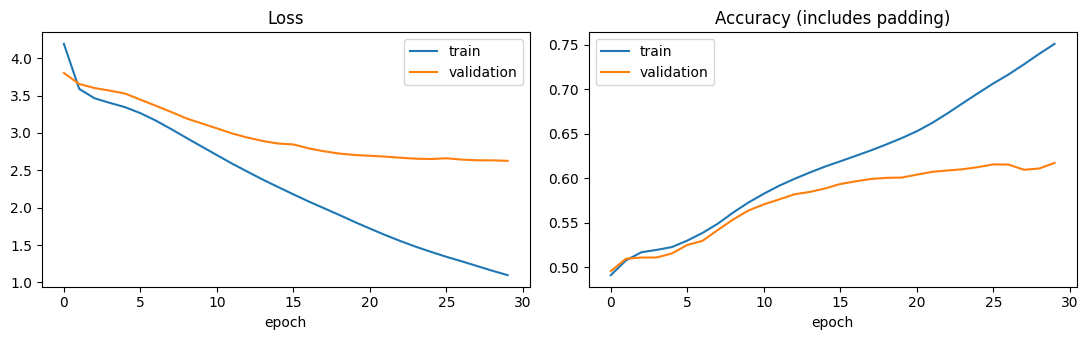

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("Accuracy (includes padding)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [13]:
# 5. Evaluation on the test set
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

loss, keras_acc = mt_model.evaluate(X_te, np.expand_dims(Y_te, -1), verbose=0)
pred_ids = mt_model.predict(X_te, verbose=0).argmax(-1)

mask = Y_te != 0                                   # real French words only
word_acc = (pred_ids[mask] == Y_te[mask]).mean()
print(f"Keras accuracy (counts padding)  : {keras_acc:.3f}")
print(f"Word accuracy (padding excluded) : {word_acc:.3f}")

def ids_to_words(ids, tok):
    return [tok.index_word[i] for i in ids if i != 0]

references = [[ids_to_words(y, fr_tok)] for y in Y_te]
hypotheses = [ids_to_words(p, fr_tok) for p in pred_ids]
bleu = corpus_bleu(references, hypotheses, smoothing_function=SmoothingFunction().method1)
print(f"Corpus BLEU score                : {bleu:.3f}")

Keras accuracy (counts padding)  : 0.622
Word accuracy (padding excluded) : 0.301
Corpus BLEU score                : 0.083


In [14]:
# Example translations from the test set
def translate(sentence):
    seq = pad_sequences(eng_tok.texts_to_sequences([clean(sentence)]), maxlen=eng_len)
    return " ".join(ids_to_words(mt_model.predict(seq, verbose=0).argmax(-1)[0], fr_tok))

for i in idx_te[:12]:
    print(f"EN  : {data.english[i]}")
    print(f"REF : {data.french[i]}")
    print(f"PRED: {translate(data.english[i])}\n")

EN  : which one will he choose?
REF : lequel choisira-t-il ?
PRED: combien coûte

EN  : the doctor's remarks reassured the patient.
REF : les remarques du docteur rassurent le patient.
PRED: le chien se se le le

EN  : the law is not always fair.
REF : la loi n'est pas toujours juste.
PRED: le remède n'est pas pas

EN  : i can't say anything now.
REF : je ne peux rien dire pour le moment.
PRED: je ne peux pas le le

EN  : i love what you're wearing.
REF : j'adore ce que vous portez.
PRED: j'apprécie que que vous vous

EN  : he came running.
REF : il est venu en courant.
PRED: il est en vite

EN  : what is all this?
REF : qu'est tout ceci ?
PRED: qu'est ce ce il

EN  : i've just finished lunch.
REF : je viens de finir de déjeuner.
PRED: j'ai besoin de de

EN  : don't talk.
REF : ne parlez pas !
PRED: ne parle pas

EN  : i was shocked to see that.
REF : je fus choquée de voir ça.
PRED: j'étais à à faire

EN  : we don't want to lose you.
REF : nous ne voulons pas vous perdre.
PRED: nous n

In [15]:
# Translating short e-commerce style sentences (the use case)
for s in ["I like this shirt.", "This is very good.", "The price is too high.",
          "Where is my order?", "I want to buy a new phone.", "Thank you very much."]:
    print(f"{s:<30} -> {translate(s)}")

I like this shirt.             -> j'aime cette chemise
This is very good.             -> c'est très très
The price is too high.         -> le est est trop trop
Where is my order?             -> où est mon
I want to buy a new phone.     -> je veux prendre une une
Thank you very much.           -> merci d'être bien


## Results and observations

| Setting | Value |
|---|---|
| Training data | 25,000 short sentence pairs (≤ 6 English words), 22,500 train / 2,500 test |
| Vocabulary | 6,205 English words, 10,193 French words |
| Training | 30 epochs, ≈ 20 minutes on CPU |
| Keras accuracy (includes padding) | 0.622 |
| **Word accuracy (padding excluded)** | **0.301** |
| **BLEU score** | **0.083** |

**What works:** the model learned frequent, short patterns well. *"I like this shirt."* → **"j'aime cette chemise"** (perfect), *"don't talk."* → **"ne parle pas"** (correct), *"I can't say anything now."* → "je ne peux pas…" (correct start). It also learned French grammar fragments such as *ne … pas* and the right subject pronouns (*je, nous, il*).

**What doesn't work:**
- **Repeated words** (*"le est est trop trop"*, *"chez chez chez"*). The decoder receives the same context vector at every step (`RepeatVector`) and never sees the word it produced before, so nothing stops it from repeating itself.
- **Wrong content words** (*doctor's remarks* → *le chien*). With only 25k examples, many words were seen just a few times.
- **Missing endings:** the decoder has no real notion of where the sentence should stop.

**Why the Keras accuracy is misleading:** French sentences are padded to 10 positions, and the model gets the padding zeros right almost every time. That inflates accuracy to 0.62, while only **30 %** of the real words are correct. This is the same lesson as in Lab 4: always check which metric actually measures the task.

**Over-fitting:** training accuracy rose to 0.75 while validation accuracy stopped improving at about 0.62. Validation loss was still slowly decreasing at epoch 30, so early stopping never triggered.

**What would make it a usable translation system for the e-commerce company:**
1. A proper encoder–decoder with **teacher forcing**: the decoder gets the previous French word as input, which prevents repetition.
2. **Attention** (Lab 11), so each output word can look at the relevant input words instead of one fixed summary vector.
3. Much more data and longer training, or, in practice, a pre-trained **Transformer** model (e.g. MarianMT `Helsinki-NLP/opus-mt-en-fr` or T5, Lab 7) fine-tuned on product texts.